<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 7 · Bayesian basics</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/bayes-rule.html">Bayes&#x27; rule</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

In applied work a prior is usually other data in disguise: last season, the other blocks, the other farms. It earns its keep when data are thin. When prior and data have matching shapes the update is a weighted average: a synthetic block that averaged $16$ t/ha over two seasons, among blocks averaging $12$, is best estimated at $13.9$ t/ha. With many farms, the farms themselves supply the prior, and each farm's mean is pulled part of the way toward the group. On synthetic data this cut next-season error for farms with one season on record from $4.26$ to $3.48$ t/ha and left ten-season farms alone. It loses on a farm that really is different, and when farms are pooled with the wrong group. With only five farms, a weakly informative prior on the between-farm spread beat a plug-in estimate of it.

Shrink any per-farm average built from a few records, then check it out of sample by record length.
:::

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
# fallcolor is the site's colour module in tools/, not an installed package.
here = [Path.cwd(), *Path.cwd().parents]
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor
fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")

[Bayes' rule](../bayes-rule.qmd) turns a prior and data into a posterior. This module is about the prior, which in applied work is other data, summarised: last season, the blocks next door, the other farms.

All data below are **synthetic**, generated with fixed seeds; none of the yields or rates describe a real farm.

## Last season as a prior: conjugate updates

When prior and data have matching shapes, called **conjugate**, the update is a weighted average you can explain in a meeting. Two pairs cover most small-sample questions: normal prior and normal data for averages such as yield; beta prior and binomial counts for rates such as defects.

**A new block's yield.** How much other blocks typically differ, set against how much one season scatters, makes the prior worth $2.25$ extra seasons of this block's own data. The synthetic numbers: other blocks average $12$ t/ha and a block's true yield typically sits $2$ t/ha from that; one season scatters $3$ t/ha around a block's true yield; the new block averaged $16$ t/ha over two seasons. Two real seasons against $2.25$ imaginary ones put the estimate a little under halfway from $12$ to $16$.

In symbols ($m_0$ prior mean, $\tau$ typical block-to-block distance, $n$ seasons with mean $\bar y$, $\sigma$ season scatter, all in t/ha), the estimate moves toward the data by a weight $w$ between 0 and 1:

$$\hat\theta = m_0 + w\,(\bar y - m_0), \qquad w = \frac{n/\sigma^2}{n/\sigma^2 + 1/\tau^2}.$$

$1/\sigma^2$ and $1/\tau^2$ are **precisions**, and precision adds: each season brings $1/\sigma^2$, the prior $1/\tau^2$, and $w$ is the data's share. So the prior is worth $\sigma^2/\tau^2 = 3^2/2^2 = 2.25$ seasons. The posterior standard deviation is $1/\sqrt{n/\sigma^2 + 1/\tau^2}$ t/ha. The loop reruns the update with $\tau$ halved and doubled, the simplest **prior sensitivity check**.

In [2]:
m0, tau, sigma = 12.0, 2.0, 3.0  # synthetic prior from other blocks, and season-to-season sd (all t/ha)
n, ybar = 2, 16.0                # new block: two seasons averaging 16 t/ha
for t in (tau / 2, tau, 2 * tau):
    prec = n / sigma**2 + 1 / t**2
    w = (n / sigma**2) / prec
    print(f"prior sd {t:.0f} t/ha: weight on own data {w:.2f}, "
          f"posterior mean {m0 + w * (ybar - m0):.1f} t/ha, posterior sd {prec**-0.5:.2f} t/ha")

prior sd 1 t/ha: weight on own data 0.18, posterior mean 12.7 t/ha, posterior sd 0.90 t/ha
prior sd 2 t/ha: weight on own data 0.47, posterior mean 13.9 t/ha, posterior sd 1.46 t/ha
prior sd 4 t/ha: weight on own data 0.78, posterior mean 15.1 t/ha, posterior sd 1.87 t/ha


The block's two seasons get weight $0.47$, so the estimate is $13.9$ t/ha with posterior standard deviation $1.46$. Halving the prior spread gives $12.7$, doubling it $15.1$. If the number of pickers to book would differ between those two, two seasons cannot settle it. For next season's yield rather than the block's long-run level, add $\sigma^2$ to the posterior variance.

**A defect rate.** The prior $\mathrm{Beta}(a, b)$ reads as $a$ imaginary defective clamshells and $b$ sound ones seen before the lot arrives. Inspect $n$, find $k$ defective, and the posterior is $\mathrm{Beta}(a + k,\ b + n - k)$, mean $(a + k)/(a + b + n)$. The prior is worth $a + b$ inspections.

The synthetic lot, from a new supplier: 3 of 25 inspected clamshells failed quality control. Last season's rate was $4\%$. Our illustrative decision rule: hold the lot if $P(\text{rate} > 5\%) > 0.8$. Three priors: flat; last season's $4\%$ weighted as one lot's worth of inspections, 25 clamshells; and weighted as the long-run inspection record, 1000 clamshells. The second loop asks how many more clamshells, failing at the observed $12\%$, each prior needs before the rule says hold.

In [3]:
k, n = 3, 25  # synthetic lot: 3 of 25 clamshells inspected failed QC
for name, (a, b) in {"flat": (1, 1), "last season, worth 25": (1, 24), "last season, worth 1000": (40, 960)}.items():
    post = stats.beta(a + k, b + n - k)
    lo, hi = post.ppf([0.05, 0.95])
    print(f"{name:24s} Beta({a}, {b}): mean {post.mean():.3f}, 90% interval {lo:.3f} to {hi:.3f}, "
          f"P(rate > 5%) {post.sf(0.05):.2f}")
hold = lambda a, b, k, n: stats.beta(a + k, b + n - k).sf(0.05) > 0.8  # illustrative rule
for name, (a, b) in {"worth 25": (1, 24), "worth 1000": (40, 960)}.items():
    m = next(m for m in range(5001) if hold(a, b, 0.12 * (25 + m), 25 + m))  # expected failures at 12%
    print(f"last season {name}: holds the lot after {m} more clamshells at 12% failing")

flat                     Beta(1, 1): mean 0.148, 90% interval 0.054 to 0.272, P(rate > 5%) 0.96
last season, worth 25    Beta(1, 24): mean 0.080, 90% interval 0.028 to 0.151, P(rate > 5%) 0.77
last season, worth 1000  Beta(40, 960): mean 0.042, 90% interval 0.032 to 0.053, P(rate > 5%) 0.10
last season worth 25: holds the lot after 4 more clamshells at 12% failing
last season worth 1000: holds the lot after 216 more clamshells at 12% failing


The flat prior gives $0.96$ and holds the lot; the light prior gives $0.77$, just short of the rule; the heavy prior gives $0.10$, because it has assumed this lot behaves like last season's, the very question asked. More inspections settle it: the light prior holds after $4$ more clamshells, the heavy one only after $216$. Weight a prior by how comparable its source is, not how large; a new supplier deserves a light one.

## Borrow strength across farms: partial pooling

With many farms you need not choose $\tau$: the farms' own spread estimates it, and each farm is pulled toward the group by an amount set by how noisy its mean is. This is **partial pooling**. For farm $j$, with raw mean $\bar y_j$ over $n_j$ seasons and standard error $s_j = \sigma/\sqrt{n_j}$ (t/ha),

$$\hat\theta_j = \hat\mu + (1 - B_j)(\bar y_j - \hat\mu), \qquad B_j = \frac{s_j^2}{s_j^2 + \hat\tau^2},$$

where $\hat\mu$ is the group centre and $\hat\tau$ the estimated between-farm standard deviation (t/ha), and $B_j$ is the share of the way farm $j$ moves to the centre. The spread estimate $\hat\tau^2$ is the spread of the raw means minus their average noise $s_j^2$, floored at zero. The centre $\hat\mu$ is a precision-weighted mean, so farms with long records count more. Using the data to set its own prior is **empirical Bayes**; Efron and Morris show its James–Stein form has lower mean squared error than the separate sample means[^1], which is why the pooled estimate beats raw means here.

In [4]:
def shrink(means, se):
    """Copy this: empirical-Bayes partial pooling. means: raw mean per group; se: its standard error.
    Returns shrunken means and tau, the estimated between-group sd, in the units of means."""
    means, se = np.asarray(means, float), np.asarray(se, float)
    tau2 = max(0.0, means.var(ddof=1) - np.mean(se**2))  # spread of the means minus the noise in them
    w = 1 / (se**2 + tau2)
    mu = np.sum(w * means) / np.sum(w)                    # group centre; precise means count more
    B = se**2 / (se**2 + tau2)                            # share of the way to pull each mean to mu
    return mu + (1 - B) * (means - mu), np.sqrt(tau2)

On a table with one row per farm-season, the call takes four lines. The pooled $\sigma$ comes only from farms with two or more seasons, since a one-season farm has no within-farm spread to add; if few farms have two seasons, our suggestion is to fall back on a historical $\sigma$ instead. The table below is a small **synthetic** one.

In [5]:
rng = np.random.default_rng(15)
seasons_on_record = rng.integers(1, 7, 8)  # synthetic: 8 farms with 1 to 6 seasons each
df = pd.DataFrame({"farm": np.repeat([f"F{j}" for j in range(8)], seasons_on_record)})
df["y"] = np.repeat(12 + 2 * rng.standard_normal(8), seasons_on_record) + 3 * rng.standard_normal(len(df))  # t/ha
# Copy this: four lines from a farm-season table to shrunken farm means
g = df.groupby("farm")["y"].agg(n_seasons="size", raw_mean="mean", var="var")
sigma = np.sqrt((g["var"] * (g["n_seasons"] - 1)).sum() / (g["n_seasons"] - 1).sum())  # pooled within-farm sd
g["shrunk_mean"], tau = shrink(g["raw_mean"], sigma / np.sqrt(g["n_seasons"]))
print(f"pooled sigma {sigma:.2f} t/ha, tau {tau:.2f} t/ha")
g.drop(columns="var").round(2)

pooled sigma 2.97 t/ha, tau 2.05 t/ha


,n_seasons,raw_mean,shrunk_mean
farm,,,
F0,6,13.95,13.65
F1,5,11.63,11.97
F2,5,13.15,13.05
F3,5,12.00,12.23
F4,2,7.92,10.42
F5,3,13.50,13.22
F6,2,14.22,13.50
F7,1,17.69,14.38


To test it, a **synthetic** program of 30 farms: true yields around $12$ t/ha with $\tau = 2$, season scatter $\sigma = 3$ treated as known, and six farms each with 1, 2, 3, 5 and 10 seasons on record.

tau_hat 1.88 t/ha; share of gap kept: one season 0.28, ten seasons 0.80


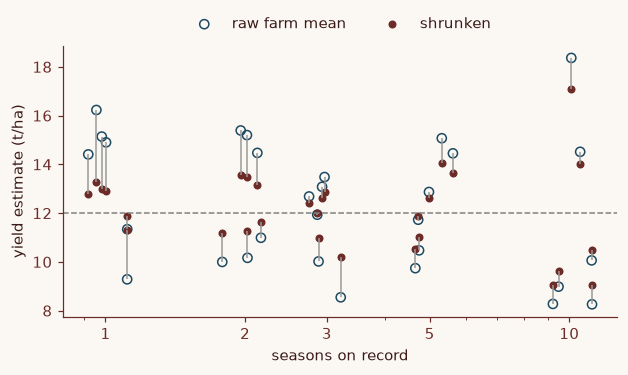

In [6]:
MU, TAU, SIGMA = 12.0, 2.0, 3.0    # synthetic: mean farm yield, between-farm sd, season-to-season sd (t/ha)
N = np.repeat([1, 2, 3, 5, 10], 6)  # seasons on record, 30 farms
SE = SIGMA / np.sqrt(N)
def seasons(rng, n=N, theta=None):  # synthetic: each farm's past mean and next season's yield (t/ha)
    theta = MU + TAU * rng.standard_normal(len(n)) if theta is None else theta
    return theta + SIGMA / np.sqrt(n) * rng.standard_normal(len(n)), theta + SIGMA * rng.standard_normal(len(n))
past, nxt = seasons(np.random.default_rng(2))
shrunk, tau_hat = shrink(past, SE)
keep = tau_hat**2 / (tau_hat**2 + SE**2)  # 1 - B
print(f"tau_hat {tau_hat:.2f} t/ha; share of gap kept: one season {keep[0]:.2f}, ten seasons {keep[-1]:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = N * np.exp(np.random.default_rng(1).uniform(-0.12, 0.12, len(N)))  # jitter on a log axis
ax.vlines(x, past, shrunk, color="0.6", lw=1)
ax.scatter(x, past, facecolors="none", edgecolors=C1, label="raw farm mean")
ax.scatter(x, shrunk, color=C3, s=18, label="shrunken")
ax.axhline(MU, color="0.5", lw=1, ls="--")
ax.set(xscale="log", xticks=[1, 2, 3, 5, 10], xticklabels=[1, 2, 3, 5, 10],
       xlabel="seasons on record", ylabel="yield estimate (t/ha)")
ax.legend(frameon=False, ncols=2, loc="lower center", bbox_to_anchor=(0.5, 1))
plt.show()

**Figure 1 | Shrinkage by record length.** One synthetic program of 30 farms. Hollow, raw farm means; filled, shrunken; dashed, the true average of all farms, $12$ t/ha.

$\hat\tau$ came out at $1.88$ t/ha against a true $2$. A one-season farm keeps $0.28$ of its distance from the centre; a ten-season farm keeps $0.80$. Next, both forecasts are scored against next season's yield over 2000 synthetic programs; the floor is $\sigma = 3$ t/ha.

In [7]:
def score(make, estimators, n=N, sims=2000, seed=1):
    # RMSE (t/ha) of next-season forecasts by seasons on record, over synthetic programs from make(rng)
    rng, sq = np.random.default_rng(seed), {k: [] for k in estimators}
    for _ in range(sims):
        past, nxt = make(rng)
        for k, f in estimators.items():
            sq[k].append((f(past) - nxt) ** 2)
    rows = {m: {k: np.sqrt(np.mean(np.array(v)[:, n == m])) for k, v in sq.items()} for m in np.unique(n)}
    rows["all farms"] = {k: np.sqrt(np.mean(v)) for k, v in sq.items()}
    return pd.DataFrame(rows).T.rename_axis("seasons on record").round(2)
raw = lambda p: p
score(seasons, {"raw mean": raw, "shrunken": lambda p: shrink(p, SE)[0]})

,raw mean,shrunken
seasons on record,,
1,4.26,3.48
2,3.65,3.37
3,3.43,3.27
5,3.27,3.20
10,3.09,3.08
all farms,3.56,3.28


For one-season farms, shrinking cut the error from $4.26$ to $3.48$ t/ha ($1 - 3.48/4.26 = 18\%$), most of the way to the floor; over all 30 farms, from $3.56$ to $3.28$. Ten-season farms barely moved, $3.09$ against $3.08$. Shrinkage never hurt here because these farms fit its assumptions exactly: one population, normal scatter.

## When shrinkage loses

Shrinkage is a bet that the farms are alike. It loses on the farm that is not, and gives up ground when farms are pooled with the wrong group.

**A farm that really is different.** Below, one farm with two seasons on record truly yields $20$ t/ha, four between-farm standard deviations above the centre; perhaps a newer planting on better ground.

In [8]:
rng, sq = np.random.default_rng(3), []
for _ in range(2000):  # synthetic: farm 6 (two seasons on record) truly yields MU + 4 * TAU = 20 t/ha
    theta = MU + TAU * rng.standard_normal(30)
    past, nxt = seasons(rng, theta=np.where(np.arange(30) == 6, MU + 4 * TAU, theta))
    sq.append([(past[6] - nxt[6]) ** 2, (shrink(past, SE)[0][6] - nxt[6]) ** 2])
print("odd farm's next-season RMSE (t/ha): raw mean {:.2f}, shrunken {:.2f}".format(*np.sqrt(np.mean(sq, axis=0))))

odd farm's next-season RMSE (t/ha): raw mean 3.66, shrunken 4.79


Shrinking raised that farm's error from $3.66$ to $4.79$ t/ha. Pooling helps on average, not on every farm: check unusual farms by hand, and put any known reason for a difference into the model.

**The wrong group.** Now the 30 farms grow two varieties with true averages $9$ and $15$ t/ha, each with $\tau = 2$ within it. One shared centre, near $12$, is wrong for both.

In [9]:
VARIETY = np.tile([0, 1], 15)  # synthetic: two varieties, true averages 9 and 15 t/ha
two_varieties = lambda rng: seasons(rng, theta=MU + np.where(VARIETY, 3.0, -3.0) + TAU * rng.standard_normal(30))
def shrink_within(p, groups=VARIETY):  # shrink each group toward its own centre
    out = p.copy()
    for g in np.unique(groups): out[groups == g] = shrink(p[groups == g], SE[groups == g])[0]
    return out
score(two_varieties, {"raw mean": raw, "shrunk to all farms": lambda p: shrink(p, SE)[0], "within variety": shrink_within})

,raw mean,shrunk to all farms,within variety
seasons on record,,,
1,4.26,3.83,3.51
2,3.65,3.53,3.40
3,3.43,3.36,3.29
5,3.27,3.24,3.23
10,3.09,3.08,3.10
all farms,3.56,3.42,3.31


One shared centre still beat raw means (one-season farms $3.83$ against $4.26$ t/ha): the variety gap inflates $\hat\tau$, weakening the pull. Shrinking within variety did better, $3.51$, close to the $3.48$ of the one-population program; over all farms, $3.56$, $3.42$ and $3.31$. Our inference: shrink toward the best prediction you have for a farm (variety, region, planting age), not the grand mean. To choose between candidate groupings, tabulate raw means by each, then backtest next-season scores of the alternatives, as this table does.

## Weakly informative priors when the group is small

With few farms, $\hat\tau$ is noisy and the plug-in rule can set it to zero, pushing every farm to one number. A **weakly informative** prior on $\tau$ rules out the absurd, a spread of 50 t/ha or of exactly zero, and lets the data choose the rest. Gelman recommends half-$t$ priors for a hierarchical standard deviation when groups are few, and shows problems with inverse-gamma "noninformative" defaults[^2].

Use `shrink_grid` when you have about five groups; otherwise `shrink`. It weights a grid of $\tau$ values by how well each explains the farm means and by a half-Cauchy prior, the one-degree-of-freedom half-$t$, then averages the shrunken estimates. Its scale, 5 t/ha, about twice the plausible between-farm spread, is our illustrative choice.

In [10]:
def shrink_grid(means, se, scale=5.0, taus=np.linspace(0.01, 15, 600)):
    """Copy this: partial pooling averaged over between-group sds tau, half-Cauchy(scale) prior on tau,
    flat prior on the centre. scale and taus are in the units of means."""
    means, se = np.asarray(means, float), np.asarray(se, float)
    v = se**2 + taus[:, None] ** 2                        # variance of each raw mean, for each tau
    V = 1 / np.sum(1 / v, axis=1)
    mu = V * np.sum(means / v, axis=1)                    # best centre for each tau
    logp = (stats.halfcauchy.logpdf(taus, scale=scale) + 0.5 * np.log(V)
            - 0.5 * np.sum(np.log(v) + (means - mu[:, None]) ** 2 / v, axis=1))
    p = np.exp(logp - logp.max())
    return (p / p.sum()) @ (mu[:, None] + (1 - se**2 / v) * (means - mu[:, None]))
N5 = np.array([1, 2, 3, 5, 10])  # five synthetic farms
SE5 = SIGMA / np.sqrt(N5)
five = lambda rng: seasons(rng, n=N5)
rng = np.random.default_rng(4)
for make, se, k in ((seasons, SE, 30), (five, SE5, 5)):
    print(f"{k} farms: plug-in tau exactly zero in {np.mean([shrink(make(rng)[0], se)[1] == 0 for _ in range(20000)]):.1%}")
score(five, {"raw mean": raw, "plug-in tau": lambda p: shrink(p, SE5)[0], "half-Cauchy prior": lambda p: shrink_grid(p, SE5)},
      n=N5, sims=20000)

30 farms: plug-in tau exactly zero in 1.2%


5 farms: plug-in tau exactly zero in 26.5%


,raw mean,plug-in tau,half-Cauchy prior
seasons on record,,,
1,4.24,3.63,3.58
2,3.67,3.48,3.43
3,3.44,3.36,3.31
5,3.27,3.26,3.22
10,3.11,3.13,3.10
all farms,3.57,3.38,3.33


With five farms, $\hat\tau$ was exactly zero in $26.5\%$ of synthetic programs (against $1.2\%$ with 30), collapsing all five forecasts to one number. The plug-in rule still beat raw means overall, $3.38$ against $3.57$ t/ha, but was slightly worse for the ten-season farm, $3.13$ against $3.11$, a gap that may be partly simulation noise. The half-Cauchy prior was best in every row, $3.33$ overall.

::: {.callout-tip}
## What this means for you

Our own recommendations, from the simulations above:

- Replace any per-farm, per-variety or per-store average that has few rows behind it with `shrink`, and shrink within the best grouping you have.
- In a gradient-boosting pipeline (our inference, not tested here): add the shrunken farm mean as a feature, computed out of fold so a farm's validation rows never feed it (see [Leakage](../leakage/leakage.ipynb)). That is smoothed target encoding with the smoothing set by the data rather than tuned by hand. Per-farm residual corrections applied after the model can be shrunk the same way.
:::

## Key takeaways

- Write every prior as data: where it came from and how many observations it is worth ($a + b$ for a beta, $\sigma^2/\tau^2$ seasons for a normal). Sources that may not be comparable get fewer.
- Score raw and shrunken versions out of sample, split by record length; expect the gain on short records only.
- Rerun any one-off decision on thin data under a weaker and a stronger prior, and report both.

## References

[^1]: Efron, B. & Morris, C. Data analysis using Stein's estimator and its generalizations. *J. Am. Stat. Assoc.* **70**, 311–319 (1975). https://doi.org/10.1080/01621459.1975.10479864
[^2]: Gelman, A. Prior distributions for variance parameters in hierarchical models (comment on article by Browne and Draper). *Bayesian Anal.* **1**, 515–534 (2006). https://doi.org/10.1214/06-BA117A

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/bayes-rule.html"><span>Previous</span>Bayes&#x27; rule</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/controls-and-randomisation.html"><span>Next</span>Controls and randomisation</a></div>
<!-- CURRICULUM_FOOTER_END -->